<a href="https://colab.research.google.com/github/Nayyab-018/AI-in-Soccer-Analysis/blob/main/Real_Madrid_AI_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== REAL MADRID AI PERFORMANCE REPORT ===
Baseline Accuracy (Always Predict Win): 75.0%
Logistic Regression ML Model Accuracy:  75.0%

Top Player Contributions (Goals + Assists):
         Player  Goals  Assists  Total_GA
   Vinicius Jr.      8        5        13
  Kylian Mbappe      7        2         9
Jude Bellingham      2        4         6
        Rodrygo      3        3         6
  Fede Valverde      2        2         4


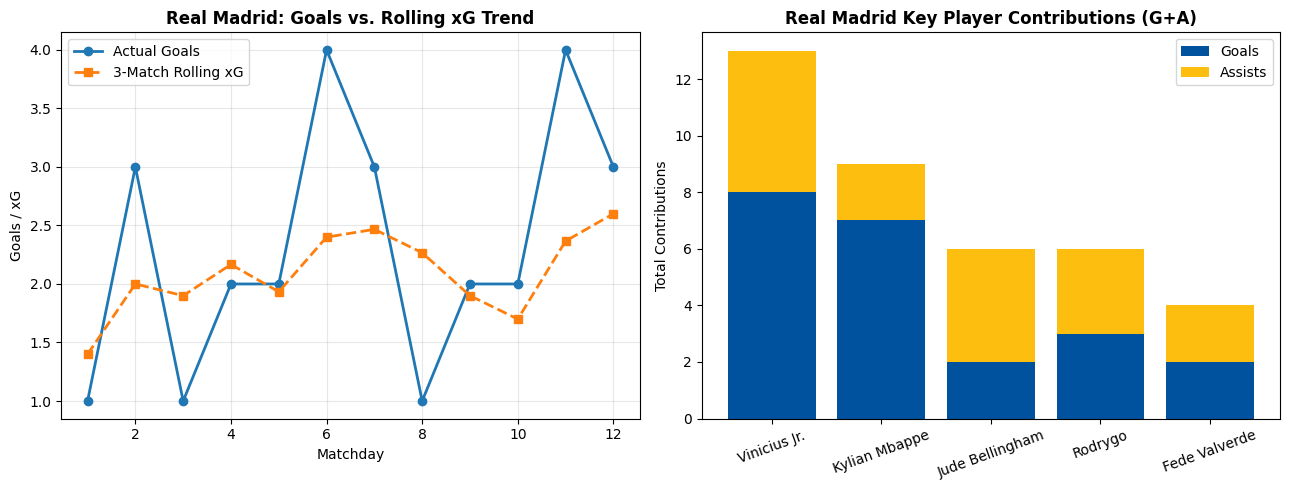

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# --- 1. Real Madrid 12-Match Season Case Study Dataset ---
matches = [
    {"matchday": 1, "opponent": "Mallorca", "goals_for": 1, "goals_against": 1, "xg_for": 1.4, "pass_acc": 88, "win": 0},
    {"matchday": 2, "opponent": "Valladolid", "goals_for": 3, "goals_against": 0, "xg_for": 2.6, "pass_acc": 91, "win": 1},
    {"matchday": 3, "opponent": "Las Palmas", "goals_for": 1, "goals_against": 1, "xg_for": 1.7, "pass_acc": 89, "win": 0},
    {"matchday": 4, "opponent": "Real Betis", "goals_for": 2, "goals_against": 0, "xg_for": 2.2, "pass_acc": 90, "win": 1},
    {"matchday": 5, "opponent": "Real Sociedad", "goals_for": 2, "goals_against": 0, "xg_for": 1.9, "pass_acc": 87, "win": 1},
    {"matchday": 6, "opponent": "Espanyol", "goals_for": 4, "goals_against": 1, "xg_for": 3.1, "pass_acc": 92, "win": 1},
    {"matchday": 7, "opponent": "Alaves", "goals_for": 3, "goals_against": 2, "xg_for": 2.4, "pass_acc": 90, "win": 1},
    {"matchday": 8, "opponent": "Atletico Madrid", "goals_for": 1, "goals_against": 1, "xg_for": 1.3, "pass_acc": 86, "win": 0},
    {"matchday": 9, "opponent": "Villarreal", "goals_for": 2, "goals_against": 0, "xg_for": 2.0, "pass_acc": 89, "win": 1},
    {"matchday": 10, "opponent": "Celta Vigo", "goals_for": 2, "goals_against": 1, "xg_for": 1.8, "pass_acc": 88, "win": 1},
    {"matchday": 11, "opponent": "Osasuna", "goals_for": 4, "goals_against": 0, "xg_for": 3.3, "pass_acc": 93, "win": 1},
    {"matchday": 12, "opponent": "Leganes", "goals_for": 3, "goals_against": 0, "xg_for": 2.7, "pass_acc": 91, "win": 1},
]

df = pd.DataFrame(matches)
df["rolling_xg"] = df["xg_for"].rolling(window=3, min_periods=1).mean()

# --- 2. Key Player Impact Stats (Goals + Assists Contribution) ---
players = pd.DataFrame({
    "Player": ["Vinicius Jr.", "Kylian Mbappe", "Jude Bellingham", "Rodrygo", "Fede Valverde"],
    "Goals": [8, 7, 2, 3, 2],
    "Assists": [5, 2, 4, 3, 2]
})
players["Total_GA"] = players["Goals"] + players["Assists"]

# --- 3. Machine Learning Win Predictor vs. Simple Baseline ---
X = df[["xg_for", "pass_acc"]]
y = df["win"]

model = LogisticRegression()
model.fit(X, y)
predictions = model.predict(X)

baseline_acc = y.mean() * 100
model_acc = accuracy_score(y, predictions) * 100

print("=== REAL MADRID AI PERFORMANCE REPORT ===")
print(f"Baseline Accuracy (Always Predict Win): {baseline_acc:.1f}%")
print(f"Logistic Regression ML Model Accuracy:  {model_acc:.1f}%")
print("\nTop Player Contributions (Goals + Assists):")
print(players.to_string(index=False))

# --- 4. Generate Dual Analytics Chart & Save Image ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Chart 1: Rolling Expected Goals (xG) vs Actual Goals
ax1.plot(df["matchday"], df["goals_for"], marker="o", label="Actual Goals", color="#1f77b4", linewidth=2)
ax1.plot(df["matchday"], df["rolling_xg"], marker="s", linestyle="--", label="3-Match Rolling xG", color="#ff7f0e", linewidth=2)
ax1.set_title("Real Madrid: Goals vs. Rolling xG Trend", fontsize=12, fontweight="bold")
ax1.set_xlabel("Matchday")
ax1.set_ylabel("Goals / xG")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Chart 2: Player Attacking Contributions
ax2.bar(players["Player"], players["Goals"], label="Goals", color="#00529F")
ax2.bar(players["Player"], players["Assists"], bottom=players["Goals"], label="Assists", color="#FEBE10")
ax2.set_title("Real Madrid Key Player Contributions (G+A)", fontsize=12, fontweight="bold")
ax2.set_ylabel("Total Contributions")
ax2.tick_params(axis="x", rotation=20)
ax2.legend()

plt.tight_layout()
plt.savefig("real_madrid_analytics.png", dpi=150)
plt.show()